<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h2>تمرین سوم: بخش <span dir="ltr">SVM</span></h2>

<p>
در این نوت‌بوک، بخش مربوط به <span dir="ltr">SVM</span> انجام شده. طبق صورت تمرین، دو دیتاست مصنوعی <span dir="ltr">Two Moons</span> و <span dir="ltr">Circles</span> ساخته میشن و بعد مدل‌های <span dir="ltr">SVM</span> با کرنل‌های مختلف روی آن‌ها بررسی میشن.
</p>

<p>
در بخش اول، روی دیتاست <span dir="ltr">Two Moons</span> سه کرنل <span dir="ltr">linear</span>، <span dir="ltr">poly</span> و <span dir="ltr">rbf</span> مقایسه میشن و مرز تصمیم هر کدوم رسم میشه. در بخش بعد، برای مدل خطی، مرز تصمیم اصلی و خطوط حاشیه با استفاده از <span dir="ltr">decision_function</span> رسم میشن و مفهوم حاشیه، متغیرهای کمکی و اثر پارامتر <span dir="ltr">C</span> توضیح داده میشه.
</p>

<p>
در انتها، همین ایده روی دیتاست <span dir="ltr">Circles</span> هم بررسی میشه تا مشخص بشه هر کرنل برای داده‌های غیرخطی چه رفتاری داره.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۱. تولید داده‌ها</h3>

<p>
در این بخش دو مجموعه داده مصنوعی ساخته میشه. دیتاست <span dir='ltr'>Two Moons</span> با <span dir='ltr'>600</span> نمونه و مقدار <span dir='ltr'>noise=0.25</span> تولید شده. دیتاست <span dir='ltr'>Circles</span> هم با <span dir='ltr'>600</span> نمونه، مقدار <span dir='ltr'>factor=0.5</span> و مقدار <span dir='ltr'>noise=0.15</span> ساخته شده.
</p>

<p>
چون هر دو دیتاست فقط دو ویژگی دارن، میشه نقاط داده و مرز تصمیم مدل‌ها را به صورت دوبعدی رسم کرد. داده‌ها با نسبت <span dir='ltr'>75/25</span> به بخش آموزش و آزمون تقسیم شدن تا مدل روی داده‌های آموزش برازش داده بشه و دقت آن روی داده‌های آزمون سنجیده بشه.
</p>

<p>
قبل از آموزش <span dir='ltr'>SVM</span>، ویژگی‌ها درون <span dir='ltr'>Pipeline</span> استانداردسازی میشن. این کار باعث میشه هر دو ویژگی در مقیاس مشابه قرار بگیرن و مدل تحت تاثیر بزرگ‌تر بودن مقیاس یکی از محور‌ها قرار نگیره.
</p>

</div>

Two Moons train/test: (450, 2) (150, 2)
Circles train/test: (450, 2) (150, 2)


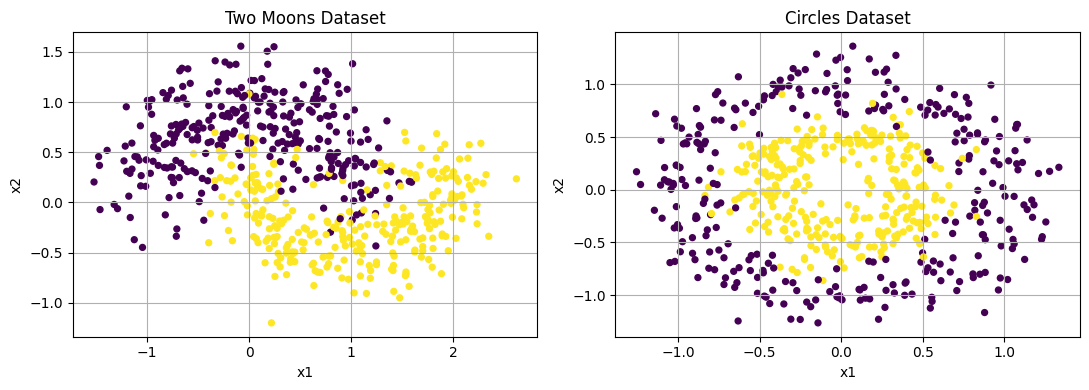

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

RANDOM_STATE = 37
TEST_SIZE = 0.25

X_moons, y_moons = make_moons(n_samples=600, noise=0.25, random_state=RANDOM_STATE)
X_circles, y_circles = make_circles(
    n_samples=600,
    factor=0.5,
    noise=0.15,
    random_state=RANDOM_STATE
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_moons
)

X_circles_train, X_circles_test, y_circles_train, y_circles_test = train_test_split(
    X_circles,
    y_circles,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_circles
)

print("Two Moons train/test:", X_moons_train.shape, X_moons_test.shape)
print("Circles train/test:", X_circles_train.shape, X_circles_test.shape)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, s=18)
plt.title("Two Moons Dataset")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(X_circles[:, 0], X_circles[:, 1], c=y_circles, s=18)
plt.title("Circles Dataset")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر شکل دیتاست‌ها</h3>

<p>
در شکل بالا، دیتاست <span dir='ltr'>Two Moons</span> به صورت دو نیم‌دایره در هم قرار گرفته دیده میشه. این شکل نشان میده که مرز جداکننده دو کلاس خطی نیست و یک خط صاف نمی‌تونه همه نقاط را خوب از هم جدا کنه.
</p>

<p>
دیتاست <span dir='ltr'>Circles</span> هم از دو حلقه داخلی و خارجی تشکیل شده. در این داده هم مرز مناسب باید حالت دایره‌ای یا خمیده داشته باشه. به همین دلیل انتظار میره کرنل‌های غیرخطی، مخصوصا <span dir='ltr'>rbf</span>، نسبت به کرنل خطی عملکرد بهتری داشته باشن.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۲. مقایسه کرنل‌های مختلف روی دیتاست <span dir='ltr'>Two Moons</span></h3>

<p>
در این بخش سه مدل <span dir='ltr'>SVM</span> جدا با کرنل‌های <span dir='ltr'>linear</span>، <span dir='ltr'>poly</span> و <span dir='ltr'>rbf</span> روی داده‌های آموزش برازش داده میشن. هدف اینه که ببینیم شکل مرز تصمیم هر کرنل با ساختار غیرخطی دیتاست <span dir='ltr'>Two Moons</span> چقدر هماهنگه.
</p>

<p>
کرنل <span dir='ltr'>linear</span> فقط یک مرز خطی ایجاد می‌کنه. کرنل <span dir='ltr'>poly</span> با استفاده از ترکیب‌های چندجمله‌ای ویژگی‌ها مرز خمیده‌تری می‌سازه و کرنل <span dir='ltr'>rbf</span> می‌تونه مرز محلی‌تر و انعطاف‌پذیرتری ایجاد کنه.
</p>

<p>
برای رسم مرز تصمیم، یک شبکه از نقاط روی صفحه ساخته میشه و مدل برای همه نقاط آن شبکه پیش‌بینی انجام میده. سپس مرز تصمیم و نقاط داده نمایش داده میشن و دقت مدل روی داده‌های آزمون گزارش میشه.
</p>

</div>

,Kernel,Test Accuracy,Support Vectors
0,linear,0.8467,154
1,poly,0.8533,162
2,rbf,0.9133,131


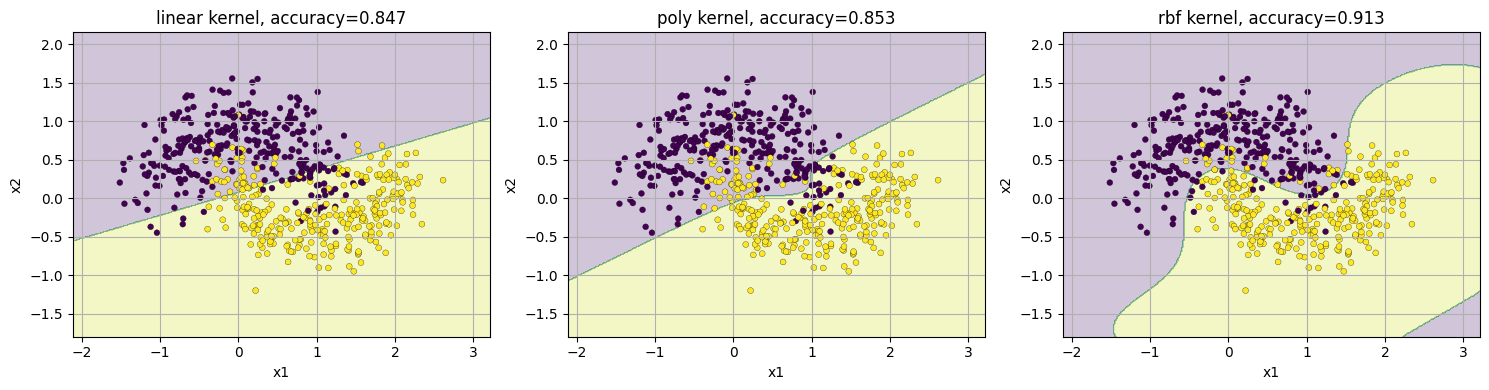

In [2]:
def build_svm_model(kernel_name):
    if kernel_name == "linear":
        svc = SVC(kernel="linear", C=1.0)
    elif kernel_name == "poly":
        svc = SVC(kernel="poly", degree=3, C=1.0, gamma="scale")
    elif kernel_name == "rbf":
        svc = SVC(kernel="rbf", C=1.0, gamma="scale")
    else:
        raise ValueError("kernel_name must be linear, poly, or rbf")

    return Pipeline([
        ("scaler", StandardScaler()),
        ("svc", svc)
    ])


def plot_decision_boundary(ax, model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 350),
        np.linspace(y_min, y_max, 350)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25)
    ax.scatter(X[:, 0], X[:, 1], c=y, s=18, edgecolor="k", linewidth=0.2)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True)


kernel_names = ["linear", "poly", "rbf"]
moons_models = {}
moons_rows = []

for kernel_name in kernel_names:
    model = build_svm_model(kernel_name)
    model.fit(X_moons_train, y_moons_train)
    y_pred = model.predict(X_moons_test)
    acc = accuracy_score(y_moons_test, y_pred)

    moons_models[kernel_name] = model
    moons_rows.append({
        "Kernel": kernel_name,
        "Test Accuracy": acc,
        "Support Vectors": int(np.sum(model.named_steps["svc"].n_support_))
    })

moons_results = pd.DataFrame(moons_rows)
display(moons_results.round(4))

plt.figure(figsize=(15, 4))

for i, kernel_name in enumerate(kernel_names, start=1):
    ax = plt.subplot(1, 3, i)
    acc = moons_results.loc[moons_results["Kernel"] == kernel_name, "Test Accuracy"].iloc[0]
    plot_decision_boundary(
        ax,
        moons_models[kernel_name],
        X_moons,
        y_moons,
        f"{kernel_name} kernel, accuracy={acc:.3f}"
    )

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر کرنل‌ها روی <span dir='ltr'>Two Moons</span></h3>

<p>
طبق جدول و نمودارهای بالا، کرنل خطی روی دیتاست <span dir='ltr'>Two Moons</span> محدودیت زیادی داره، چون فقط می‌تونه یک خط یا یک مرز تقریبا خطی بین دو کلاس بسازه. در حالی که شکل واقعی داده‌ها خمیده‌ست و دو کلاس به صورت نیم‌دایره‌ای در هم قرار گرفتن.
</p>

<p>
کرنل <span dir='ltr'>poly</span> نسبت به کرنل خطی کمی انعطاف بیشتری داره و مرز غیرخطی‌تری تولید می‌کنه، اما در این اجرا اختلاف آن با کرنل خطی زیاد نیست. دقت تست برای کرنل خطی حدود <span dir='ltr'>0.8467</span> و برای کرنل چندجمله‌ای حدود <span dir='ltr'>0.8533</span> شده.
</p>

<p>
بهترین نتیجه مربوط به کرنل <span dir='ltr'>rbf</span> است که دقت تست آن حدود <span dir='ltr'>0.9133</span> شده. دلیل این نتیجه اینه که <span dir='ltr'>rbf</span> می‌تونه مرز تصمیم خمیده‌تر و متناسب‌تری با شکل دو نیم‌دایره بسازه. بنابراین برای این دیتاست، کرنل غیرخطی <span dir='ltr'>rbf</span> انتخاب مناسب‌تری نسبت به کرنل خطی است.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۳. تحلیل حاشیه خطی و متغیرهای کمکی</h3>

<p>
در این بخش مدل <span dir='ltr'>SVM</span> خطی روی دیتاست <span dir='ltr'>Two Moons</span> بررسی میشه. هدف این بخش فقط رسیدن به بالاترین دقت نیست، بلکه می‌خوایم مرز تصمیم، خطوط حاشیه و نقش نمونه‌هایی که نزدیک مرز قرار دارن را بهتر ببینیم.
</p>

<p>
خروجی <span dir='ltr'>decision_function</span> برای هر نقطه یک مقدار عددی میده. سطحی که مقدار آن برابر صفر باشه، مرز اصلی تصمیم است. سطوح <span dir='ltr'>+1</span> و <span dir='ltr'>-1</span> هم خطوط حاشیه را نشان میدن. در نمودار، این خطوط به صورت خط‌چین رسم میشن.
</p>

<p>
چون دیتاست <span dir='ltr'>Two Moons</span> با یک خط صاف به طور کامل جداشدنی نیست، مدل خطی به <span dir='ltr'>Soft Margin</span> نیاز دارد. در این حالت متغیرهای کمکی یا <span dir='ltr'>Slack Variables</span> اجازه میدن بعضی نمونه‌ها داخل حاشیه قرار بگیرن یا حتی اشتباه دسته‌بندی بشن.
</p>

</div>

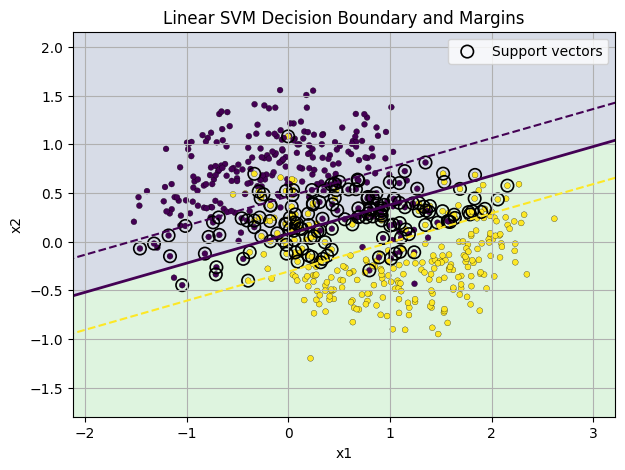

Linear SVM test accuracy: 0.8467
Number of support vectors: 154


In [3]:
linear_model = moons_models["linear"]

def plot_linear_margin(ax, model, X, y, title):
    scaler = model.named_steps["scaler"]
    svc = model.named_steps["svc"]

    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 350),
        np.linspace(y_min, y_max, 350)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    decision_values = model.decision_function(grid).reshape(xx.shape)

    ax.contourf(xx, yy, decision_values > 0, alpha=0.20)
    ax.contour(xx, yy, decision_values, levels=[0], linewidths=2)
    ax.contour(xx, yy, decision_values, levels=[-1, 1], linestyles="--", linewidths=1.5)

    ax.scatter(X[:, 0], X[:, 1], c=y, s=18, edgecolor="k", linewidth=0.2)

    support_vectors_original = scaler.inverse_transform(svc.support_vectors_)
    ax.scatter(
        support_vectors_original[:, 0],
        support_vectors_original[:, 1],
        s=80,
        facecolors="none",
        edgecolors="black",
        linewidths=1.2,
        label="Support vectors"
    )

    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True)


plt.figure(figsize=(7, 5))
ax = plt.gca()
plot_linear_margin(ax, linear_model, X_moons, y_moons, "Linear SVM Decision Boundary and Margins")
plt.legend()
plt.show()

linear_accuracy = accuracy_score(y_moons_test, linear_model.predict(X_moons_test))
print("Linear SVM test accuracy:", round(linear_accuracy, 4))
print("Number of support vectors:", int(np.sum(linear_model.named_steps["svc"].n_support_)))

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تابع هدف <span dir='ltr'>Soft Margin SVM</span></h3>

<p>تابع هدف <span dir='ltr'>SVM</span> با حاشیه نرم به صورت زیر نوشته میشه:</p>

<p><span dir='ltr'>min<sub>w,b,ξ</sub> 1/2 ||w||<sup>2</sup> + C Σ ξ<sub>i</sub></span></p>

<p>با قیدهای <span dir='ltr'>y<sub>i</sub>(w<sup>T</sup>φ(x<sub>i</sub>) + b) ≥ 1 - ξ<sub>i</sub></span> و <span dir='ltr'>ξ<sub>i</sub> ≥ 0</span>.</p>

<p>جمله <span dir='ltr'>1/2 ||w||²</span> تلاش می‌کنه حاشیه مدل بزرگ‌تر بشه. جمله <span dir='ltr'>C Σ ξ_i</span> جریمه نمونه‌هایی است که داخل حاشیه میفتن یا اشتباه دسته‌بندی میشن. متغیرهای <span dir='ltr'>ξ_i</span> هم مقدار این نقض حاشیه را نشان میدن.</p>

<p>اگر <span dir='ltr'>C</span> بزرگ‌تر بشه، مدل خطاها و نقض حاشیه را سخت‌تر جریمه می‌کنه؛ پس معمولا حاشیه باریک‌تر میشه و مدل تلاش می‌کنه داده‌های آموزش را دقیق‌تر جدا کنه. اگر <span dir='ltr'>C</span> کوچک‌تر باشه، مدل خطای بیشتری را قبول می‌کنه و معمولا حاشیه پهن‌تری می‌سازه.</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۴. اثر تغییر مقدار <span dir='ltr'>C</span></h3>

<p>
برای بررسی اثر <span dir='ltr'>C</span>، مدل خطی با چند مقدار مختلف این پارامتر آموزش داده شده. در هر حالت، مرز تصمیم و خطوط حاشیه رسم میشن تا مشخص بشه تغییر میزان جریمه خطا چه اثری روی شکل حاشیه و تعداد بردارهای پشتیبان دارد.
</p>

<p>
در حالت کلی، مقدار کوچک‌تر <span dir='ltr'>C</span> باعث مدل نرم‌تر و حاشیه بازتر میشه، چون مدل خطاهای بیشتری را تحمل می‌کنه. مقدار بزرگ‌تر <span dir='ltr'>C</span> مدل را سخت‌گیرتر می‌کنه و معمولا تعداد نمونه‌هایی که اجازه نقض حاشیه دارن کمتر میشه.
</p>

</div>

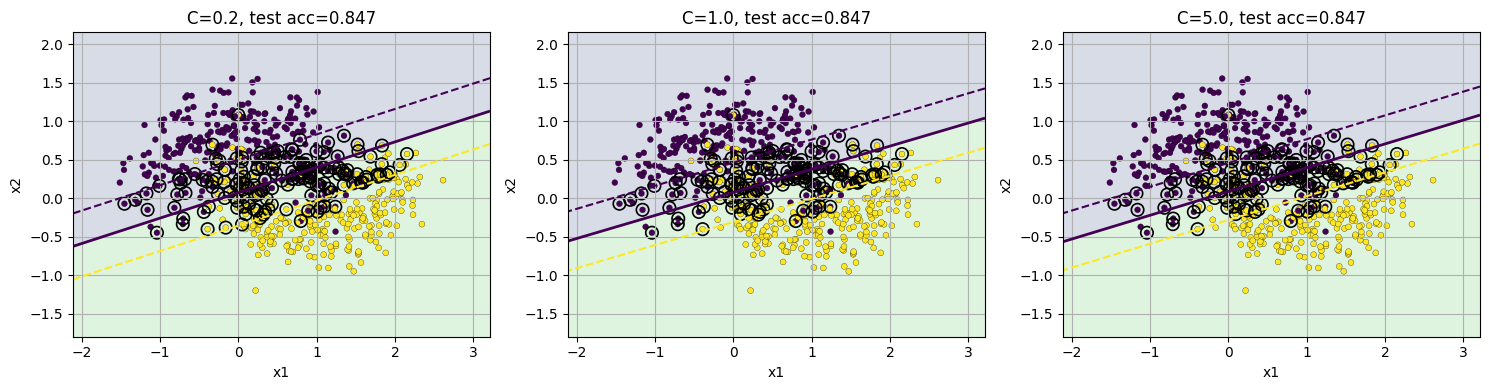

,C,Train Accuracy,Test Accuracy,Support Vectors
0,0.2,0.8400,0.8467,163
1,1.0,0.8444,0.8467,154
2,5.0,0.8400,0.8467,152


In [4]:
c_values = [0.2, 1.0, 5.0]
c_rows = []

plt.figure(figsize=(15, 4))

for i, c_value in enumerate(c_values, start=1):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="linear", C=c_value))
    ])
    model.fit(X_moons_train, y_moons_train)

    train_acc = accuracy_score(y_moons_train, model.predict(X_moons_train))
    test_acc = accuracy_score(y_moons_test, model.predict(X_moons_test))
    support_count = int(np.sum(model.named_steps["svc"].n_support_))

    c_rows.append({
        "C": c_value,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Support Vectors": support_count
    })

    ax = plt.subplot(1, 3, i)
    plot_linear_margin(ax, model, X_moons, y_moons, f"C={c_value}, test acc={test_acc:.3f}")

plt.tight_layout()
plt.show()

c_results = pd.DataFrame(c_rows)
display(c_results.round(4))

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر اثر <span dir='ltr'>C</span></h3>

<p>
طبق جدول بالا، تغییر مقدار <span dir='ltr'>C</span> از <span dir='ltr'>0.2</span> تا <span dir='ltr'>5.0</span> در این اجرا دقت تست مدل خطی را تغییر زیادی نداده و دقت تست تقریبا ثابت مانده. دلیلش اینه که مشکل اصلی این داده، خطی نبودن مرز بین دو کلاس است و تغییر <span dir='ltr'>C</span> نمی‌تونه محدودیت یک مرز خطی را کامل برطرف کنه.
</p>

<p>
با افزایش <span dir='ltr'>C</span>، تعداد بردارهای پشتیبان کمی کمتر شده. این با انتظار کلی سازگاره، چون مدل سخت‌گیرتر میشه و تلاش می‌کنه حاشیه را با خطای کمتر تنظیم کنه. با این حال، چون داده‌ها به صورت غیرخطی پخش شدن، تغییر <span dir='ltr'>C</span> به تنهایی باعث بهبود واضح عملکرد نشده.
</p>

<p>
پس در این مسئله، انتخاب کرنل مناسب اثر مهم‌تری از تغییر دادن مقدار <span dir='ltr'>C</span> دارد. برای دیتاستی مثل <span dir='ltr'>Two Moons</span>، کرنل <span dir='ltr'>rbf</span> بهتر می‌تونه شکل واقعی مرز را مدل کند.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۵. بررسی دیتاست <span dir='ltr'>Circles</span></h3>

<p>
در صورت تمرین علاوه بر دیتاست <span dir='ltr'>Two Moons</span>، دیتاست <span dir='ltr'>Circles</span> هم با پارامترهای مشخص تولید شده. برای کامل‌تر شدن بررسی، همان سه کرنل <span dir='ltr'>linear</span>، <span dir='ltr'>poly</span> و <span dir='ltr'>rbf</span> روی این دیتاست هم اجرا شدن.
</p>

<p>
این داده از دو حلقه داخلی و خارجی ساخته شده و مرز مناسب برای جدا کردن آن‌ها باید حالت دایره‌ای داشته باشه. بنابراین انتظار میره کرنل خطی عملکرد ضعیف‌تری داشته باشه و کرنل <span dir='ltr'>rbf</span> بهتر با ساختار داده هماهنگ بشه.
</p>

</div>

,Kernel,Test Accuracy,Support Vectors
0,linear,0.5933,444
1,poly,0.6000,442
2,rbf,0.9800,111


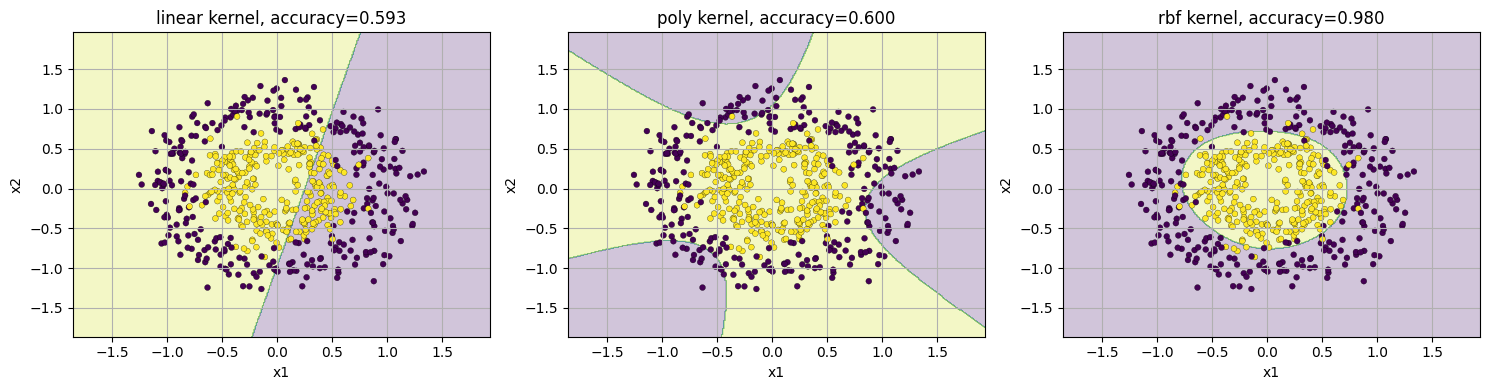

In [5]:
circle_models = {}
circle_rows = []

for kernel_name in kernel_names:
    model = build_svm_model(kernel_name)
    model.fit(X_circles_train, y_circles_train)
    y_pred = model.predict(X_circles_test)
    acc = accuracy_score(y_circles_test, y_pred)

    circle_models[kernel_name] = model
    circle_rows.append({
        "Kernel": kernel_name,
        "Test Accuracy": acc,
        "Support Vectors": int(np.sum(model.named_steps["svc"].n_support_))
    })

circle_results = pd.DataFrame(circle_rows)
display(circle_results.round(4))

plt.figure(figsize=(15, 4))

for i, kernel_name in enumerate(kernel_names, start=1):
    ax = plt.subplot(1, 3, i)
    acc = circle_results.loc[circle_results["Kernel"] == kernel_name, "Test Accuracy"].iloc[0]
    plot_decision_boundary(
        ax,
        circle_models[kernel_name],
        X_circles,
        y_circles,
        f"{kernel_name} kernel, accuracy={acc:.3f}"
    )

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>تفسیر دیتاست <span dir='ltr'>Circles</span></h3>

<p>
در دیتاست <span dir='ltr'>Circles</span>، دو کلاس به شکل حلقه‌های داخلی و خارجی قرار گرفتن. به همین دلیل یک مرز خطی نمی‌تونه آن‌ها را خوب جدا کنه. دقت تست کرنل خطی حدود <span dir='ltr'>0.5933</span> و کرنل چندجمله‌ای حدود <span dir='ltr'>0.6000</span> شده که نشان میده این دو مدل برای این شکل داده مناسب نیستن.
</p>

<p>
کرنل <span dir='ltr'>rbf</span> در این داده عملکرد خیلی بهتری داشته و دقت تست آن حدود <span dir='ltr'>0.9800</span> شده. دلیلش اینه که <span dir='ltr'>rbf</span> می‌تونه مرز تصمیم خمیده و نزدیک به شکل حلقه‌ای بسازه.
</p>

<p>
این نتیجه نشان میده که انتخاب کرنل در <span dir='ltr'>SVM</span> به شکل داده وابسته‌ست. اگر مرز واقعی بین کلاس‌ها غیرخطی باشه، استفاده از کرنل غیرخطی می‌تونه اختلاف زیادی در عملکرد مدل ایجاد کنه.
</p>

</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">

<h3>۶. جمع‌بندی</h3>

<p>
در این تمرین، مدل <span dir='ltr'>SVM</span> با کرنل‌های مختلف روی داده‌های دوبعدی بررسی شد. روی دیتاست <span dir='ltr'>Two Moons</span>، کرنل <span dir='ltr'>rbf</span> بهترین عملکرد را داشت، چون مرز تصمیم خمیده‌تری می‌سازه و با ساختار غیرخطی داده بهتر هماهنگ میشه.
</p>

<p>
در بخش حاشیه خطی، مرز تصمیم اصلی و خطوط حاشیه با استفاده از <span dir='ltr'>decision_function</span> رسم شدن. همچنین تابع هدف <span dir='ltr'>Soft Margin SVM</span> نوشته شد و نقش جمله مربوط به حاشیه، جمله جریمه، متغیرهای کمکی و پارامتر <span dir='ltr'>C</span> توضیح داده شد.
</p>

<p>
نتیجه کلی اینه که برای داده‌هایی که ذاتا غیرخطی هستن، تغییر دادن <span dir='ltr'>C</span> به تنهایی کافی نیست و انتخاب کرنل مناسب اهمیت بیشتری دارد. در هر دو دیتاست <span dir='ltr'>Two Moons</span> و <span dir='ltr'>Circles</span>، کرنل <span dir='ltr'>rbf</span> نسبت به کرنل خطی عملکرد بهتری نشان داد.
</p>

</div>